# Claudius — figures

Made **only from saved results** in `results/`; nothing is fitted here and `curlew`, `torch`
and `surfepy` are not needed.

**Opened block.** The model volume is split at `SPLIT_Y`, where the unit thicknesses change most
along the cut, and the two halves are opened towards the viewer about a hinge at the back: the
smaller half a lot, so its cut face shows the contacts along *x* where the units thin and thicken,
the larger half a little. The larger half is cut again by a vertical section at `SECTION_X`, which
faces the viewer; between it and the viewer the surfaces are see-through, and the contacts are
traced on the section. One row per
model (`MODELS`), LDI above Surfe, from one perspective camera. The scenes are built with PyVista
(`exploded3d.build_opened`) and rendered by Blender without a window (`render_exploded.py`).
Intermediate scenes and renders go to `renders/`.

## Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from PIL import Image

sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, exploded3d
import figstyle
import exploded3d
import claudius_inputs
figstyle.apply()

RES_DIR = claudius_inputs.RESULTS_DIR
FIG_DIR = Path("./figures")
RENDER_DIR = Path("./renders")
FIG_DIR.mkdir(parents=True, exist_ok=True)

data = claudius_inputs.load_processed()
names, box = data["horizon_names"], data["box"]

## Opened block

### Settings

- `SPLIT_Y`: the *y* of the split. 900 m is where the unit thicknesses vary most along a cut at
  constant *y* (the summed standard deviation of the three unit thicknesses along it, from the LDI
  surfaces), so the two cut faces show the largest thickness changes.
- `SECTION_X`: the *x* of the section on the larger half (*y* < `SPLIT_Y`). 1200 m cuts through the
  middle of the large fold in D, where D's relief is largest (about 680 m); `GHOST_ALPHA` is the opacity of the surfaces in front of it (0
  removes them).
- `ANGLE_LEFT`, `ANGLE_RIGHT`: how far each half turns about the hinge (degrees); the hinge is
  the back edge of the split (`x` = the box's lower *x*), and the viewer is on the +*x* side. The
  larger half turns a little, so its section faces the viewer; the smaller one turns a lot, so its
  cut face shows the horizons along *x* where the thicknesses change most.
- `AZIMUTH`, `ELEVATION`, `DISTANCE`: the perspective camera, aimed at the split (azimuth 90 looks
  along −*x*, straight down the split towards the hinge; less swings it towards the smaller half); a
  shorter `DISTANCE` gives a stronger perspective. The lens is set to fit both halves.
- The looks, as in the other 3D figures: `OCCLUSION` darkens the gaps between nested sheets,
  `MATTE` takes off the plastic sheen, `BACKFACE_DARKEN` shades undersides, `SHEEN` and
  `RIM_LIGHT` lift stacked sheets and their edges apart, `TEXTURE` gives the sheets a fine rock
  grain, and `WORLD_STRENGTH`, `SUN_ENERGY` set the light.
- `GLASS`: a faint framed pane of glass at the section, so the cut reads as a plane; its opacity
  is kept low so the traces on the section show through.

In [2]:
MODELS = ["ldi_seis5x5b_w20", "surfe_seis5x5b_w20"]   # results/meshes_<MODEL>.npz, one row each: the seismic-line runs of 06b and 06c
# (the evenly spaced 40% runs are "ldi_cut0.4" and "surfe_cut0.4")
# The figure is saved under the first model's sampling, so that the paper's fig06_claudius_opened (the 40% runs) is not overwritten.
SAMPLING_TAG = MODELS[0].split("_", 1)[1]
FIG_NAME = "fig06_claudius_opened" if SAMPLING_TAG == "cut0.4" else f"fig06_claudius_opened_{SAMPLING_TAG.replace('.', 'p')}"
SPLIT_Y = 900.0                   # m
SECTION_X = 1200.0                # m
GHOST_ALPHA = 0.08
ANGLE_LEFT, ANGLE_RIGHT = 10.0, 37.0   # degrees: the larger half (y < SPLIT_Y) turns a little, the smaller one a lot
AZIMUTH, ELEVATION = 90.0, 18.0   # degrees; 90 looks along -x, straight down the split at the hinge
DISTANCE = 16000.0                # m, camera to the centre of the opened block
MIN_AREA = 2000.0                 # m², drop surface specks smaller than this
SEISMIC_LINES_ON = True           # draw the seismic lines of a seismic-sampled model on the youngest surface (weakly)
LINE_RADIUS = 3.0                 # m, thin: they are a hint of where the data are, not a feature
LINE_LIFT = 5.0                   # m above the surface, so they do not sink into it
LINE_WHITE = 0.55                 # how far the youngest surface's colour is mixed towards white for the lines (0 = same colour)
RIM_RADIUS = 16.0                 # m, the traced contacts on the cut faces and the section
SMOOTH_EDGES = 60.0               # m, smoothing of the traces and of the cut edges
SHEET_COLORS = [matplotlib.colors.to_hex(figstyle.ramp()(t)) for t in np.linspace(0.9, 0.1, len(names))]
EXT_COLOR_3D = "#FF1FA8"          # interior extrema: bright pink
RESOLUTION = (1800, 1200)         # px
ENGINE, SAMPLES = "EEVEE", 64
OCCLUSION = 0.03 * np.ptp(box[:, 0])   # m, ambient occlusion reach (None = off)
MATTE = True
BACKFACE_DARKEN = 0.3
SHEEN = 0.25                      # brighter where a sheet turns away: stacked sheets separate (0 = off)
RIM_LIGHT = 1.5                   # a second sun from behind, for the sheet edges (0 = off)
TEXTURE, TEXTURE_SIZE = 0.0, 30.0   # rock grain: strength (0 = smooth) and size (m)
WORLD_STRENGTH, SUN_ENERGY = 0.35, 3.5
GLASS = dict(alpha=0.1, color="#DCE8F0", frame="#4E6A80", frame_alpha=0.7, frame_radius=6.0)   # the section's pane (None = none)
HORIZON_LABELS = [f"H{k}" for k in range(len(names))]   # H0 (youngest, A) to H3 (D), as in the paper
KEY_WIDTH = 1.0                  # in, the plan-view key over the top right of the last render (its height follows)
KEY_REGION = 0.45                 # the right share of the rows the key may sit in

### Render

Each model's saved surfaces are cleaned, split and opened; each interior extremum gets the first
saved shell that closes. Both scenes use one camera, fitted to the opened block (the same for both
models), so the rows compare directly.

In [3]:
renders, n_ext = {}, {}
cam = None
for model in MODELS:
    meshes = np.load(RES_DIR / f"meshes_{model}.npz")
    summary = json.loads((RES_DIR / f"{model}.json").read_text())["comparison"]
    n_ext[model] = summary["extrema"]["maximum"] + summary["extrema"]["minimum"]
    sheets = exploded3d.sheets_from_saved(meshes, min_area=MIN_AREA)
    # the seismic lines of this model's sampling, draped on the youngest surface: where its sheet crosses each line's plane
    lines_cfg = json.loads((RES_DIR / f"{model}.json").read_text()).get("parameters", {}).get("lines")
    seis_lines = []
    if SEISMIC_LINES_ON and lines_cfg:
        line_x, line_y = claudius_inputs.seismic_lines(claudius_inputs.pick_extent(data["horizons"]), lines_cfg["n_x"],
                                                       lines_cfg["n_y"], lines_cfg.get("bounds", True))
        for a in line_x:
            seis_lines += exploded3d.plane_traces(sheets[0], (1.0, 0.0, 0.0), (a, 0.0, 0.0), lift=LINE_LIFT, smooth=SMOOTH_EDGES)
        for b in line_y:
            seis_lines += exploded3d.plane_traces(sheets[0], (0.0, 1.0, 0.0), (0.0, b, 0.0), lift=LINE_LIFT, smooth=SMOOTH_EDGES)
    base = np.array([int(SHEET_COLORS[0].lstrip("#")[k:k + 2], 16) for k in (0, 2, 4)]) / 255
    LINE_COLOR = "#" + "".join(f"{int(round(255 * c)):02x}" for c in base + LINE_WHITE * (1.0 - base))
    shells = [(p, exploded3d.shell_from_saved(meshes, e)) for e, p in enumerate(meshes["ext_points"])]
    scene, corners = exploded3d.build_opened(
        RENDER_DIR / f"opened_{model}", surfaces=sheets, box=box, split_y=SPLIT_Y, hinge_x=float(box[0, 0]),
        angle=(ANGLE_LEFT, ANGLE_RIGHT), section_x=SECTION_X, ghost_alpha=GHOST_ALPHA, colors=SHEET_COLORS, extrema=shells,
        extremum_color=EXT_COLOR_3D, rim_radius=RIM_RADIUS, rim_smooth=SMOOTH_EDGES, edge_smooth=SMOOTH_EDGES,
        lines=seis_lines, line_color=LINE_COLOR, line_radius=LINE_RADIUS,
        min_area=MIN_AREA, occlusion=OCCLUSION, matte=MATTE, backface_darken=BACKFACE_DARKEN, sheen=SHEEN,
        rim_light=RIM_LIGHT, texture=TEXTURE, texture_size=TEXTURE_SIZE, glass=GLASS,
        world_strength=WORLD_STRENGTH, sun_energy=SUN_ENERGY,
    )
    if cam is None:
        # aimed at the split (y = SPLIT_Y), so the camera looks down it towards the hinge
        aim = 0.5 * (corners.min(0) + corners.max(0))
        aim[1] = SPLIT_Y
        cam = exploded3d.perspective_camera(corners, AZIMUTH, ELEVATION, RESOLUTION, distance=DISTANCE, target=aim)
    if model == MODELS[0]:
        # where to label each horizon: level with the solid left end of its sheet on the larger
        # half (at the section), and left of its see-through part
        label_px = {}
        t = np.radians(-ANGLE_LEFT)                    # the larger half turns by -ANGLE_LEFT (viewer on +x)
        rot = np.array([[np.cos(t), -np.sin(t), 0.0], [np.sin(t), np.cos(t), 0.0], [0.0, 0.0, 1.0]])
        pivot = np.array([box[0, 0], SPLIT_Y, 0.0])
        lx = np.ptp(box[:, 0])
        for k, sh in enumerate(sheets):
            p = np.asarray(sh.points)
            edge = p[p[:, 1] < box[0, 1] + 0.02 * np.ptp(box[:, 1])]
            ends = [edge[np.abs(edge[:, 0] - xe) < 0.04 * lx] for xe in (SECTION_X, box[1, 0])]
            ends = [np.median(e, axis=0) for e in ends if len(e)]
            if ends:
                uv = exploded3d.project((np.array(ends) - pivot) @ rot.T + pivot, cam, RESOLUTION)
                label_px[k] = (uv[:, 0].min(), uv[0, 1])
    renders[model] = exploded3d.render(scene, RENDER_DIR / f"opened_{model}.png", cam=cam, resolution=RESOLUTION,
                                       engine=ENGINE, samples=SAMPLES)
    print(f"{model}: {n_ext[model]} interior extrema; rendered {renders[model]}")

ldi_seis5x5b_w20: 0 interior extrema; rendered renders/opened_ldi_seis5x5b_w20.png
surfe_seis5x5b_w20: 23 interior extrema; rendered renders/opened_surfe_seis5x5b_w20.png


### Compose

The two renders cropped to one box (one scale), stacked, each titled with its model and its
interior extrema. The horizons are labelled H0–H3 on the first row,
beside the left end of each sheet, and the pink of the extrema is keyed beside the title of the row
that has them. The plan-view key sits over the top right of the last render: the block from above as the
camera sees it, its two halves turned about the hinge as in the renders, the opening angles, the
section (the glass pane, blue), the see-through part in front of it (hatched), and an eye where
the camera stands, looking along `AZIMUTH`.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array


wrote
  figures/fig06_claudius_opened_seis5x5b_w20.pdf
  figures/fig06_claudius_opened_seis5x5b_w20.png


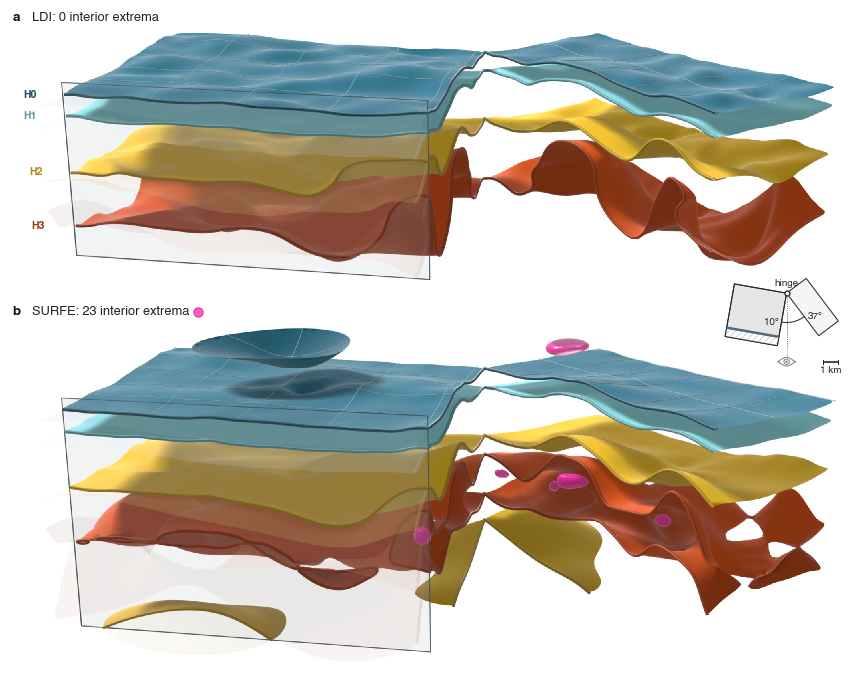

In [4]:
from matplotlib.patches import Polygon

DPI = 300
imgs = {m: np.asarray(Image.open(p).convert("RGBA")) for m, p in renders.items()}
# one horizontal crop for all (one scale); each row cropped to its own content vertically
alpha = np.maximum.reduce([im[..., 3] for im in imgs.values()])
cols = np.flatnonzero(alpha.max(0) > 8)
pad = 10
c0, c1 = max(cols[0] - pad, 0), min(cols[-1] + pad + 1, alpha.shape[1])
row_span, crop = {}, {}
for m, im in imgs.items():
    rows = np.flatnonzero(im[..., 3].max(1) > 8)
    row_span[m] = (max(rows[0] - pad, 0), min(rows[-1] + pad + 1, im.shape[0]))
    crop[m] = im[row_span[m][0]:row_span[m][1], c0:c1]


def panel_pixels(arr, w_in, h_in):
    # Resample to the panel's size at DPI ourselves, on premultiplied alpha (no halo at the edges).
    size = (max(1, round(w_in * DPI)), max(1, round(h_in * DPI)))
    return np.asarray(Image.fromarray(arr).convert("RGBa").resize(size, Image.Resampling.LANCZOS).convert("RGBA"))


INK, MUTED, GLASS_INK = "0.15", "0.45", GLASS["frame"]
fs = lambda s=9, bold=False: figstyle._fp(size=s, bold=bold)
W = figstyle.PRINT_WIDTH
left, right, top, bottom = 0.30, 0.04, 0.26, 0.06      # left: room for the horizon labels
w = W - left - right
px_in = w / (c1 - c0)                                  # inches per render pixel
h = {m: px_in * crop[m].shape[0] for m in MODELS}
# The plan-view key: the block from above (y to the right, +x down), its two halves turned about
# the hinge as in the renders, the section on the larger half and the see-through part in front
# of it, and an eye where the camera stands, looking at the block along AZIMUTH.
(x0, y0b), (x1, y1b) = box[0, :2], box[1, :2]
lx = x1 - x0


def turned(pts, deg):
    # (x, y) points turned about the hinge by deg, as build_opened turns each half; returned as (y, x) to plot
    t = np.radians(deg)
    q = np.asarray(pts, dtype=float) - (x0, SPLIT_Y)
    xy = np.c_[np.cos(t) * q[:, 0] - np.sin(t) * q[:, 1], np.sin(t) * q[:, 0] + np.cos(t) * q[:, 1]] + (x0, SPLIT_Y)
    return xy[:, ::-1]


turn_a, turn_b = -ANGLE_LEFT, ANGLE_RIGHT              # the viewer is on +x: half a turns by -angle, b by +angle
half_a = turned([(x0, y0b), (x1, y0b), (x1, SPLIT_Y), (x0, SPLIT_Y)], turn_a)
half_b = turned([(x0, SPLIT_Y), (x1, SPLIT_Y), (x1, y1b), (x0, y1b)], turn_b)
front = turned([(SECTION_X, y0b), (x1, y0b), (x1, SPLIT_Y), (SECTION_X, SPLIT_Y)], turn_a)
section = turned([(SECTION_X, y0b), (SECTION_X, SPLIT_Y)], turn_a)
hinge = np.array([SPLIT_Y, x0])

drawn = np.vstack([half_a, half_b])
target = np.array([SPLIT_Y, 0.5 * (drawn[:, 1].min() + drawn[:, 1].max())])   # the camera aims at the split
az = np.radians(AZIMUTH)
look = np.array([-np.cos(az), np.sin(az)])               # target to camera, as (y, x): +x and -y for azimuth < 90
eye_at = target + look * (drawn[:, 1].max() + 0.30 * lx - target[1]) / look[1]
eye_w, eye_h = 0.17 * lx, 0.08 * lx                      # the eye's half-width (across the gaze) and half-height
sb_x = drawn[:, 1].max() + 0.30 * lx                     # the scale bar, below the block on the right
pts = np.vstack([drawn, eye_at + (eye_w + 0.05 * lx) * np.array([[-1, 0], [1, 0], [0, 1]])])
span_y = np.ptp(pts[:, 0])
key_xlim = (pts[:, 0].min() - 0.03 * span_y, pts[:, 0].max() + 0.03 * span_y)
key_ylim = (max(pts[:, 1].max(), sb_x + 0.25 * lx), drawn[:, 1].min() - 0.18 * lx)

# The plan-view key sits over the top right of the last render (the renders are transparent),
# its bottom just above that render's content in the key's columns.
kw = KEY_WIDTH
kh = kw * abs(np.diff(key_ylim)[0]) / np.diff(key_xlim)[0]          # the key's height follows its drawing
gap = 0.30
H = top + sum(h.values()) + (len(MODELS) - 1) * gap + bottom
fig = figstyle.print_figure(height=H)
titled, axes = [], {}
y_top = H - top
for i, model in enumerate(MODELS):
    y0 = y_top - h[model]
    ax = fig.add_axes((left / W, y0 / H, w / W, h[model] / H))
    ax.imshow(panel_pixels(crop[model], w, h[model]), interpolation="none",
              extent=(0, crop[model].shape[1], crop[model].shape[0], 0))     # data units: crop pixels
    ax.set_axis_off()
    axes[model] = (ax, y0)
    y_top = y0 - gap
    label = "SURFE" if model.startswith("surfe") else "LDI"
    t = ax.set_title(f"{label}: {n_ext[model]} interior extrema", loc="left", color="0.15",
                     fontproperties=figstyle._fp(size=11))
    titled.append((t, "ab"[i], n_ext[model] > 0))

# Horizon labels on the first row, left of each sheet's left end, in a darker shade of its colour.
ax0 = axes[MODELS[0]][0]
for k, (u, v) in label_px.items():
    ink = 0.72 * np.array(matplotlib.colors.to_rgb(SHEET_COLORS[k]))
    ax0.text(u - c0 - 14, v - row_span[MODELS[0]][0], HORIZON_LABELS[k], ha="right", va="center", color=ink,
             fontproperties=fs(9, bold=True), clip_on=False)

last, y_last = crop[MODELS[-1]], axes[MODELS[-1]][1]
under = np.flatnonzero(last[:, int(last.shape[1] - kw / px_in):, 3].max(1) > 8)
key_y0 = y_last + h[MODELS[-1]] - px_in * (under[0] if len(under) else 0) + 0.03
kax = fig.add_axes(((W - right - kw) / W, key_y0 / H, kw / W, kh / H), zorder=5)
kax.add_patch(Polygon(half_a, closed=True, fc="0.90", ec=INK, lw=0.6, joinstyle="miter"))
kax.add_patch(Polygon(half_b, closed=True, fc="0.96", ec=INK, lw=0.6, joinstyle="miter"))
with matplotlib.rc_context({"hatch.linewidth": 0.3}):
    kax.add_patch(Polygon(front, closed=True, fc="white", ec="0.65", lw=0.0, hatch="//////"))
kax.add_patch(Polygon(half_a, closed=True, fc="none", ec=INK, lw=0.6, joinstyle="miter"))
kax.plot(*section.T, color=GLASS_INK, lw=1.5, solid_capstyle="butt")
# the closed split for reference, and the opening angles
closed = np.array([hinge, (SPLIT_Y, x1)])
kax.plot(*closed.T, color=MUTED, lw=0.5, ls=(0, (1, 1.5)))
r = 0.55 * lx
for deg in (turn_a, turn_b):
    t = np.radians(np.linspace(0.0, deg, 30))
    arc = np.c_[SPLIT_Y + r * np.sin(t), x0 + r * np.cos(t)]          # (y, x) to plot
    kax.plot(*arc.T, color=INK, lw=0.6)
    # each angle beside the end of its arc, on the side its half turned to
    tip = (arc[-1, 0] + np.sign(deg) * 0.06 * lx, arc[-1, 1])
    kax.text(*tip, f"{abs(deg):g}°", ha="left" if deg > 0 else "right", va="center", color=INK,
             fontproperties=fs(8.5))
kax.plot(*hinge, marker="o", ms=3.0, mfc="white", mec=INK, mew=0.8, zorder=6)
kax.text(hinge[0], hinge[1] - 0.10 * lx, "hinge", ha="center", va="bottom", color=INK, fontproperties=fs(8.5))
# the camera: a small line-drawn eye (lids meeting in points, an iris ring and a pupil), its long
# axis across the line of sight, and the line of sight to where the camera aims (under the block)
gaze = -look
across = np.array([gaze[1], -gaze[0]])
tt = np.linspace(-1.0, 1.0, 61)
bulge = np.sin(0.5 * np.pi * (1 - np.abs(tt))) ** 1.3                # rounder lids with sharp corners
lid = lambda sgn: eye_at + np.outer(eye_w * tt, across) + np.outer(sgn * eye_h * bulge, gaze)
almond = np.vstack([lid(+1), lid(-1)[::-1]])
eye_ink = "0.5"
kax.plot(*np.array([eye_at + 1.25 * eye_h * gaze, target]).T, color=MUTED, lw=0.5, ls=(0, (1, 1.5)), zorder=0)
kax.add_patch(Polygon(almond, closed=True, fc="white", ec=eye_ink, lw=0.6, joinstyle="miter", zorder=6))
kax.add_patch(matplotlib.patches.Circle(eye_at, 0.62 * eye_h, fc="none", ec=eye_ink, lw=0.6, zorder=7))
kax.add_patch(matplotlib.patches.Circle(eye_at, 0.27 * eye_h, fc=eye_ink, ec="none", zorder=7))
# a 1 km scale bar
sb_y = drawn[:, 0].max()
kax.plot([sb_y - 1000.0, sb_y], [sb_x, sb_x], color=INK, lw=1.0, solid_capstyle="butt")
for yy in (sb_y - 1000.0, sb_y):
    kax.plot([yy, yy], [sb_x - 0.04 * lx, sb_x + 0.04 * lx], color=INK, lw=0.6)
kax.text(sb_y - 500.0, sb_x + 0.08 * lx, "1 km", ha="center", va="top", color=INK, fontproperties=fs(8.5))
kax.set_xlim(*key_xlim)
kax.set_ylim(*key_ylim)
kax.set_aspect("equal", adjustable="box")
kax.set_axis_off()

fig.canvas.draw()
renderer = fig.canvas.get_renderer()
pink_face = matplotlib.colors.to_hex(0.7 * np.array(matplotlib.colors.to_rgb(EXT_COLOR_3D)) + 0.3)
for t, letter, has_ext in titled:
    bb = t.get_window_extent(renderer).transformed(fig.transFigure.inverted())
    fig.text(bb.x0 - 0.10 / W, bb.y0, letter, ha="right", va="bottom", color="0.08",
             fontproperties=figstyle._fp(bold=True, size=8.0 / figstyle.TEXT_SCALE))
    if has_ext:                                        # the pink of the extrema in the renders, as a key
        fig.add_artist(Line2D([bb.x1 + 0.07 / W], [0.5 * (bb.y0 + bb.y1)], ls="", marker="o", ms=5.5,
                              mfc=pink_face, mec=EXT_COLOR_3D, mew=0.7, transform=fig.transFigure))

written = figstyle.save(fig, FIG_DIR / FIG_NAME)
print("wrote", *written, sep="\n  ")
plt.show()